# Phân tích dữ liệu thu thập được

Notebook này đọc file `data/slop.sqlite` (chỉ đọc, không sửa gì) và trình bày lại các số liệu chính của báo cáo tiến độ: dữ liệu thu được, nhãn, tỷ lệ tên bịa của từng model, mức trùng giữa các model, dữ liệu hỏi lại, độ bền qua các phiên bản và các gói ra đời sau mốc dữ liệu.

**Cách chạy** (trong thư mục gốc của repo):

```bash
uv sync --group notebook
uv run jupyter lab notebooks/phan-tich-du-lieu.ipynb
```

Chạy lần lượt từ trên xuống (menu *Run → Run All Cells*). Toàn bộ mất khoảng 2–4 phút.

**Lưu ý đạo đức:** notebook chỉ in số liệu tổng hợp. Không in danh sách tên bịa chưa có trên PyPI, vì kẻ xấu có thể đăng ký ngay các tên đó. Nếu tự khám phá thêm, đừng đưa danh sách đó ra ngoài.

## 0. Chuẩn bị

Kết nối tới cơ sở dữ liệu và khai báo vài hằng số. Ba model chính luôn dùng cùng một màu trong mọi biểu đồ: Llama xanh dương, DeepSeek cam, GLM xanh ngọc.

In [15]:
import os, sys, sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tìm thư mục gốc của repo (chứa pyproject.toml) và chuyển vào đó.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

DB = ROOT / "data" / "slop.sqlite"
conn = sqlite3.connect(f"file:{DB}?mode=ro", uri=True, timeout=120)  # chỉ đọc

LABELS_VERSION = "rules-v3"
MODELS = {  # mã trong CSDL -> tên hiển thị
    "llama31-8b-deepinfra": "Llama 3.1 8B",
    "deepseek-v41-flash-deepinfra": "DeepSeek V4.1 Flash",
    "glm53-internal": "GLM 5.3",
}
COLORS = {"Llama 3.1 8B": "#2a78d6", "DeepSeek V4.1 Flash": "#eb6834", "GLM 5.3": "#1baf7a"}
HALLUCINATED = ["hallucinated_absent", "registered_hallucination"]

def q(sql, params=()):
    """Chạy một câu SQL, trả về bảng pandas."""
    return pd.read_sql_query(sql, conn, params=params)

plt.rcParams.update({"figure.figsize": (7, 3.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})
snap = q("SELECT snapshot_id, n_projects FROM pypi_snapshots")
print("CSDL:", DB, f"({DB.stat().st_size / 1e9:.1f} GB)")
print("Snapshot PyPI:", snap.iloc[0, 0], "-", f"{snap.iloc[0, 1]:,}".replace(",", "."), "project")

CSDL: /home/thanhnc/developments/master-road/slopsquatting/data/slop.sqlite (4.2 GB)
Snapshot PyPI: pypi-20261112T031153-43535604 - 937.845 project


## 1. Đã thu được những gì

Mỗi dòng trong bảng `generations` là một câu trả lời của LLM. Mỗi câu hỏi có 3 tác vụ:
- `code`: sinh code;
- `pkgs_for_code`: hỏi "cần gói nào để chạy đoạn code này";
- `pkgs_for_prompt`: hỏi "gói nào hữu ích cho bài toán này".

Số câu trả lời lớn hơn 18.033 là vì có thêm các lần hỏi lại.

In [16]:
gen = q("""SELECT model_key AS model, replace(replace(task_id, 'spracklen_', ''), '_v1', '') AS task,
                  COUNT(*) AS answers, SUM(error IS NOT NULL) AS errors
           FROM generations GROUP BY 1, 2""")
gen.pivot_table(index="model", columns="task", values="answers", fill_value=0).astype(int)

task,code,pkgs_for_code,pkgs_for_prompt
model,,,
deepseek-v3-deepinfra,2320,2320,2320
deepseek-v31-deepinfra,2320,2320,2320
deepseek-v32-deepinfra,2320,2320,2320
deepseek-v4-flash-0731-deepinfra,2320,2320,2320
deepseek-v41-flash-deepinfra,20121,20121,20121
glm53-deepinfra,2330,2330,2330
glm53-internal,18033,18033,18033
llama31-8b-deepinfra,20238,20238,20238
llama33-70b-deepinfra,2450,2450,2450


## 2. Nhãn của các tên gói

Mỗi tên gói (đếm tên không trùng) được gắn một nhãn. Ý nghĩa:

| Nhãn | Nghĩa |
|---|---|
| `hallucinated_absent` | tên bịa, chưa có trên PyPI |
| `real` | gói thật bình thường |
| `placeholder` | bản giữ chỗ hoặc project rỗng |
| `stdlib` | tên module có sẵn trong Python (`os`, `json`…) |
| `registered_hallucination` | có trên PyPI nhưng có bằng chứng là tên bịa bị người khác đăng ký |
| `known_malicious` | gói độc hại đã biết |

,label,names,needs_review,share
0,hallucinated_absent,41365,0,0.6673
1,real,19436,0,0.3135
2,placeholder,656,653,0.0106
3,stdlib,313,0,0.0050
4,registered_hallucination,155,14,0.0025
5,known_malicious,67,0,0.0011


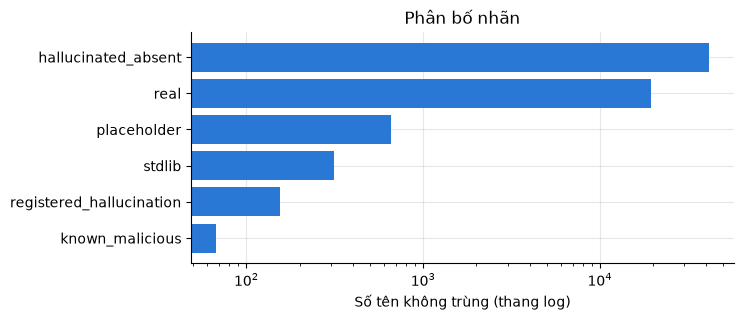

In [17]:
labels = q("SELECT label, COUNT(*) AS names, SUM(needs_review) AS needs_review FROM labels WHERE labeler_version = ? GROUP BY 1 ORDER BY 2 DESC",
           (LABELS_VERSION,))
labels["share"] = (labels["names"] / labels["names"].sum()).round(4)
display(labels)

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(labels["label"][::-1], labels["names"][::-1], color="#2a78d6")
ax.set_xscale("log")
ax.set_xlabel("Số tên không trùng (thang log)")
ax.set_title("Phân bố nhãn")
plt.show()

## 3. Tỷ lệ tên bịa theo model

Chỉ tính **lần hỏi gốc** (lần hỏi đầu tiên của mỗi câu hỏi) và hai cách lấy tên của Spracklen và cộng sự (2025): từ lệnh `pip install` và từ câu trả lời dạng danh sách. Tên thư viện chuẩn không tính.

- **Lượt gợi ý:** mỗi lần một tên xuất hiện trong một câu trả lời. Một tên có thể được gợi ý nhiều lần.
- **Tên không trùng:** đếm mỗi tên một lần.

In [18]:
mentions = q("""
    SELECT v.model_key, v.task_id, v.prompt_id, v.norm_name, l.label
    FROM v_mentions v JOIN labels l ON l.norm_name = v.norm_name AND l.labeler_version = ?
    WHERE v.root_sample_idx = 0 AND v.method IN ('pip_install', 'llm_list') AND v.model_key IN (?, ?, ?)
""", (LABELS_VERSION, *MODELS))
mentions = mentions[mentions["label"] != "stdlib"].copy()
mentions["model"] = pd.Categorical(mentions["model_key"].map(MODELS), categories=list(MODELS.values()), ordered=True)
mentions["hallucinated"] = mentions["label"].isin(HALLUCINATED)

rows = []
for model, g in mentions.groupby("model", observed=True):
    names = g.groupby("norm_name")["label"].first()
    rows.append({
        "model": model,
        "câu hỏi có tên gói": g["prompt_id"].nunique(),
        "lượt gợi ý": len(g),
        "lượt gợi ý / câu hỏi": round(len(g) / g["prompt_id"].nunique(), 1),
        "tỷ lệ lượt gợi ý là tên bịa": round(g["hallucinated"].mean(), 4),
        "tỷ lệ câu hỏi có tên bịa": round(g.groupby("prompt_id")["hallucinated"].any().mean(), 4),
        "tên không trùng": len(names),
        "tên bịa không trùng": int(names.isin(HALLUCINATED).sum()),
    })
summary = pd.DataFrame(rows).set_index("model")
summary

,câu hỏi có tên gói,lượt gợi ý,lượt gợi ý / câu hỏi,tỷ lệ lượt gợi ý là tên bịa,tỷ lệ câu hỏi có tên bịa,tên không trùng,tên bịa không trùng
model,,,,,,,
Llama 3.1 8B,17894,208190,11.6,0.2463,0.6881,38737,28132
DeepSeek V4.1 Flash,17492,104151,6.0,0.0328,0.1150,9652,2055
GLM 5.3,17903,320994,17.9,0.0504,0.3528,23017,9544


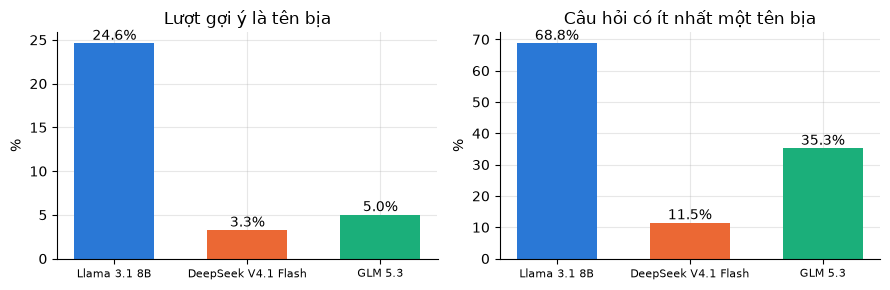

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, col, title in [(axes[0], "tỷ lệ lượt gợi ý là tên bịa", "Lượt gợi ý là tên bịa"),
                       (axes[1], "tỷ lệ câu hỏi có tên bịa", "Câu hỏi có ít nhất một tên bịa")]:
    vals = summary[col] * 100
    ax.bar(vals.index, vals.values, color=[COLORS[m] for m in vals.index], width=0.6)
    for x, v in zip(vals.index, vals.values):
        ax.text(x, v, f"{v:.1f}%", ha="center", va="bottom")
    ax.set_title(title); ax.set_ylabel("%"); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

**Đọc kết quả:** Llama bịa nhiều nhất tính theo lượt gợi ý. GLM bịa ít trên mỗi lượt, nhưng liệt kê nhiều tên trong một câu trả lời, nên tỷ lệ câu hỏi có tên bịa vẫn cao. Với kẻ tấn công, con số quan trọng là tỷ lệ câu hỏi có tên bịa.

### 3.1. Tên bịa theo tác vụ

Hỏi thẳng "gói nào hữu ích" (`pkgs_for_prompt`) có làm LLM bịa nhiều hơn so với hỏi gói để chạy một đoạn code cụ thể không?

In [20]:
by_task = (mentions.assign(task=mentions["task_id"].str.replace("spracklen_", "").str.replace("_v1", ""))
           .pivot_table(index="model", columns="task", values="hallucinated", aggfunc="mean", observed=True).round(4))
by_task

task,code,pkgs_for_code,pkgs_for_prompt
model,,,
Llama 3.1 8B,0.1039,0.2008,0.2654
DeepSeek V4.1 Flash,0.0218,0.0234,0.0354
GLM 5.3,0.0248,0.0285,0.0575


### 3.2. Số tên bịa mới tăng thế nào khi hỏi thêm câu hỏi

Lấy các câu hỏi theo một thứ tự ngẫu nhiên cố định, rồi đếm số tên bịa không trùng tích lũy. Nếu đường còn đi lên thẳng thì hỏi thêm vẫn còn ra nhiều tên bịa mới. Nếu đường cong dẹt dần thì các tên bịa bắt đầu lặp lại.

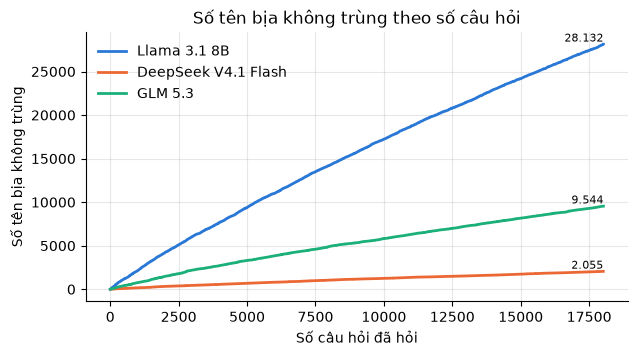

In [21]:
rng = np.random.default_rng(0)
prompts = mentions["prompt_id"].unique()
order = pd.Series(np.arange(len(prompts)), index=rng.permutation(prompts))

fig, ax = plt.subplots()
for model, g in mentions[mentions["hallucinated"]].groupby("model", observed=True):
    first_seen = g.assign(pos=g["prompt_id"].map(order)).groupby("norm_name")["pos"].min().sort_values()
    curve = pd.Series(np.arange(1, len(first_seen) + 1), index=first_seen.values)
    ax.plot(curve.index, curve.values, color=COLORS[model], lw=2, label=model)
    ax.annotate(f"{len(first_seen):,}".replace(",", "."), (curve.index[-1], curve.values[-1]), fontsize=8, ha="right", va="bottom")
ax.set_xlabel("Số câu hỏi đã hỏi"); ax.set_ylabel("Số tên bịa không trùng"); ax.legend(frameon=False)
ax.set_title("Số tên bịa không trùng theo số câu hỏi")
plt.show()

## 4. Các model có bịa ra cùng tên không

Một tên bịa do nhiều model cùng gợi ý là mục tiêu tốt cho kẻ tấn công: đăng ký một tên là đánh trúng nhiều model cùng lúc.

In [22]:
sets = {m: set(g.loc[g["hallucinated"], "norm_name"]) for m, g in mentions.groupby("model", observed=True)}
L, D, G = (sets[m] for m in MODELS.values())
overlap = pd.DataFrame({
    "nhóm": ["chỉ Llama", "chỉ DeepSeek", "chỉ GLM", "Llama và DeepSeek", "Llama và GLM", "DeepSeek và GLM", "cả ba model"],
    "số tên bịa": [len(L - D - G), len(D - L - G), len(G - L - D), len(L & D), len(L & G), len(D & G), len(L & D & G)],
})
display(overlap)
# Số model cùng bịa ra mỗi tên, và số câu hỏi mà tên đó xuất hiện.
n_models = pd.Series({n: sum(n in s for s in sets.values()) for n in L | D | G})
n_prompts = mentions[mentions["hallucinated"]].groupby("norm_name")["prompt_id"].nunique()
pd.DataFrame({"số tên": n_models.value_counts().sort_index(),
              "trung vị số câu hỏi gặp tên": n_prompts.groupby(n_models).median()}).rename_axis("số model cùng bịa")

,nhóm,số tên bịa
0,chỉ Llama,25506
1,chỉ DeepSeek,653
2,chỉ GLM,6870
3,Llama và DeepSeek,1057
4,Llama và GLM,2329
5,DeepSeek và GLM,1105
6,cả ba model,760


,số tên,trung vị số câu hỏi gặp tên
số model cùng bịa,,
1,33029,1.0
2,2211,2.0
3,760,4.0


**Đọc kết quả:** phần lớn tên bịa chỉ do một model sinh ra. Tên do cả ba model cùng bịa ít hơn hẳn, nhưng mỗi tên xuất hiện ở nhiều câu hỏi hơn.

## 5. Tên bịa có đăng ký được không

PyPI từ chối tên trùng hoặc quá giống tên đã có (bỏ dấu `-_.`, đổi `l`/`i` thành `1`, `o` thành `0`). Bảng dưới là tỷ lệ tên bịa chưa có trên PyPI mà vẫn đăng ký được, tức kẻ tấn công có thể lấy.

In [23]:
status = q("SELECT norm_name, registrable, reason FROM package_status WHERE snapshot_id = ?", (snap.iloc[0, 0],)).set_index("norm_name")
absent = mentions[mentions["label"] == "hallucinated_absent"][["model", "norm_name"]].drop_duplicates()
absent = absent.join(status, on="norm_name")
absent.groupby("model", observed=True).agg(tên_bịa_chưa_có=("norm_name", "count"),
                                        tỷ_lệ_đăng_ký_được=("registrable", "mean")).round(4)

,tên_bịa_chưa_có,tỷ_lệ_đăng_ký_được
model,,
Llama 3.1 8B,28004,0.9552
DeepSeek V4.1 Flash,2049,0.9302
GLM 5.3,9526,0.9370


## 6. Hỏi lại cùng câu hỏi: LLM có lặp lại tên bịa không

Mỗi model có 250 cặp (tên bịa, câu hỏi). Câu hỏi được hỏi lại 10 lần; mỗi lần gộp cả ba tác vụ.
- **lặp lại:** tỷ lệ lần hỏi có gợi ý đúng tên bịa ban đầu;
- **ít nhất một lần:** tỷ lệ cặp mà tên đó xuất hiện ít nhất một lần.

Với Llama và DeepSeek, lần hỏi số 0 chính là lần sinh ra tên được chọn (nên luôn trúng), vì vậy chỉ tính lần 1–9. Phần hỏi lại của GLM chạy qua DeepInfra, cả 10 lần, nên số của GLM không so trực tiếp được với hai model kia.

In [24]:
REASK = {"glm53-internal": "glm53-deepinfra"}  # GLM: chọn tên từ máy nội bộ, hỏi lại qua DeepInfra
sel = q("SELECT norm_name, model_key, prompt_id FROM selections WHERE selection_id = 'variants-v1'")
rows = []
for mk, g in sel.groupby("model_key"):
    ask = REASK.get(mk, mk)
    first = 0 if mk in REASK else 1
    ps = list(g["prompt_id"].unique())
    v = q(f"""SELECT prompt_id, root_sample_idx AS s, norm_name FROM v_mentions
              WHERE model_key = ? AND method IN ('pip_install','llm_list') AND root_sample_idx >= ?
              AND prompt_id IN ({",".join("?" * len(ps))})""", (ask, first, *ps)).drop_duplicates()
    hits = v.merge(g[["norm_name", "prompt_id"]]).groupby(["norm_name", "prompt_id"])["s"].nunique()
    k = g.set_index(["norm_name", "prompt_id"]).join(hits).fillna({"s": 0})["s"]
    rows.append({"model": MODELS[mk], "số cặp": len(k), "lặp lại": round(k.mean() / (10 - first), 4),
                 "ít nhất một lần": round((k > 0).mean(), 4)})
pd.DataFrame(rows).set_index("model").loc[list(MODELS.values())]

,số cặp,lặp lại,ít nhất một lần
model,,,
Llama 3.1 8B,250,0.4884,0.808
DeepSeek V4.1 Flash,250,0.6347,0.868
GLM 5.3,250,0.1928,0.468


## 7. Độ bền của tên bịa qua các phiên bản model

Hỏi các phiên bản khác cùng họ đúng những câu hỏi đã chọn. Phiên bản đó có gợi ý lại tên bịa của bản gốc không? Kết quả tách theo số model chính (Llama, DeepSeek, GLM) cùng bịa ra tên đó.

Phần này dùng lại hàm phân tích trong `slopcollect.detect.persistence`.

In [25]:
from slopcollect.detect import persistence

pers = persistence.analyse(str(DB))
rows = []
for base, fam in pers["families"].items():
    entries = [(fam["label"] + " (bản gốc, lần 1–9)", fam["base"])] + [(v["label"], v) for v in fam["versions"].values() if v.get("pairs")]
    for name, x in entries:
        r = {"phiên bản": name, "mọi cặp": x["any"]}
        for k_models, gx in x["any_by_n_models"].items():
            r[f"tên do {k_models} model bịa"] = gx["any"]
        rows.append(r)
pd.DataFrame(rows).set_index("phiên bản")

,mọi cặp,tên do 1 model bịa,tên do 2 model bịa,tên do 3 model bịa
phiên bản,,,,
"Llama 3.1 8B (07/2024) (bản gốc, lần 1–9)",0.808,0.8182,0.5000,1.0000
Llama 3.3 70B (12/2024),0.072,0.0519,0.0833,0.7143
Llama 4 Scout (04/2025),0.064,0.0433,0.1667,0.5714
"DeepSeek V4.1 Flash 1017 (10/2026) (bản gốc, lần 1–9)",0.868,0.7979,0.9178,0.9036
DeepSeek V3 (12/2024),0.416,0.1170,0.5068,0.6747
DeepSeek V3.1 (08/2025),0.396,0.1489,0.4110,0.6627
DeepSeek V3.2 (12/2025),0.424,0.2128,0.4384,0.6506
DeepSeek V4 Flash 0731 (07/2026),0.440,0.1489,0.5616,0.6627


**Đọc kết quả:** tên chỉ một model bịa ít khi xuất hiện lại ở phiên bản khác. Tên nhiều model cùng bịa thì phần lớn vẫn được gợi ý lại. Lưu ý: họ Llama chỉ có 7 cặp ở nhóm "3 model", quá ít để kết luận.

## 8. Metadata: tên bịa đã bị đăng ký khác gói thật ở đâu

So sánh trung vị một số metadata giữa gói thật do LLM gợi ý và các nhóm còn lại. Tuổi gói tính theo lần tải lên đầu tiên, kể cả các bản đã bị xóa.

In [26]:
meta = q("""
    SELECT l.label, pf.first_release_at, pf.downloads_last_month, pf.github_stars, pf.n_releases, pf.description_len
    FROM labels l JOIN package_features pf ON pf.norm_name = l.norm_name AND pf.pypi_name IS NOT NULL
    WHERE l.labeler_version = ? AND l.label IN ('real', 'registered_hallucination', 'placeholder', 'known_malicious')
""", (LABELS_VERSION,))
now = pd.Timestamp(snap.iloc[0, 0].split("-")[1][:8], tz="UTC")
meta["tuổi_ngày"] = (now - pd.to_datetime(meta["first_release_at"], utc=True, errors="coerce")).dt.days
meta.groupby("label").agg(số_gói=("label", "size"), tuổi_ngày=("tuổi_ngày", "median"),
                          lượt_tải_30_ngày=("downloads_last_month", "median"), sao_github=("github_stars", "median"),
                          số_bản_phát_hành=("n_releases", "median"), độ_dài_mô_tả=("description_len", "median"))

,số_gói,tuổi_ngày,lượt_tải_30_ngày,sao_github,số_bản_phát_hành,độ_dài_mô_tả
label,,,,,,
placeholder,656,2662.0,0.0,14.0,0.0,71.0
real,19181,3186.0,12972.0,123.0,13.0,2473.0
registered_hallucination,132,574.0,67.0,0.0,1.0,9.5


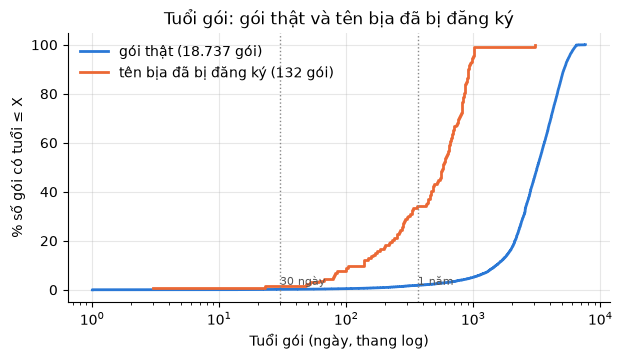

In [27]:
# Đường tích lũy: tại mỗi tuổi X, bao nhiêu phần trăm số gói có tuổi không quá X ngày.
fig, ax = plt.subplots()
for label, name, color in [("real", "gói thật", "#2a78d6"), ("registered_hallucination", "tên bịa đã bị đăng ký", "#eb6834")]:
    x = np.sort(meta.loc[meta["label"] == label, "tuổi_ngày"].dropna().clip(lower=1).values)
    ax.step(x, np.arange(1, len(x) + 1) / len(x) * 100, where="post", color=color, lw=2,
            label=f"{name} ({len(x):,} gói)".replace(",", "."))
for d, t in [(30, "30 ngày"), (365, "1 năm")]:
    ax.axvline(d, color="#888888", lw=1, ls=":"); ax.text(d, 2, t, fontsize=8, color="#555555", ha="left")
ax.set_xscale("log"); ax.set_xlabel("Tuổi gói (ngày, thang log)"); ax.set_ylabel("% số gói có tuổi ≤ X")
ax.legend(frameon=False, loc="upper left"); ax.set_title("Tuổi gói: gói thật và tên bịa đã bị đăng ký")
plt.show()

**Đọc biểu đồ cẩn thận:** đường của "tên bịa đã bị đăng ký" dừng ở khoảng 1.000 ngày. Lý do là phần lớn nhóm này được gắn nhãn chính vì ra đời sau mốc dữ liệu của Llama (12/2023), nên tuổi của chúng không thể vượt khoảng 1.020 ngày. Khác biệt về tuổi ở đây một phần do cách gắn nhãn, không hoàn toàn là đặc điểm tự nhiên của nhóm.

## 9. Gói có thật nhưng ra đời sau mốc dữ liệu của model

Mốc dữ liệu là thời điểm cuối cùng của dữ liệu dùng để huấn luyện model. Model không thể biết một gói ra đời sau mốc của nó. Nếu model vẫn gợi ý đúng tên, tên đó do model bịa ra, rồi về sau mới có người đăng ký.

Mốc lấy từ `configs/cutoffs.toml`: Llama theo công bố chính thức, DeepSeek và GLM theo thông tin cộng đồng.

In [28]:
from slopcollect.detect import cutoff

cut = cutoff.analyse(str(DB))
pd.DataFrame([{"model": m, "mốc": x["cutoff"], "nguồn mốc": x["cutoff_source"], "tên có trên PyPI": x["existing_names"],
               "ra đời sau mốc": x["after_cutoff"], "tỷ lệ": x["after_cutoff_share"], "theo nhãn": x["after_by_label"]}
              for m, x in cut["models"].items()]).set_index("model")

,mốc,nguồn mốc,tên có trên PyPI,ra đời sau mốc,tỷ lệ,theo nhãn
model,,,,,,
deepseek-v3-deepinfra,2024-07-31,cộng đồng,971,14,0.0144,"{'real': 11, 'registered_hallucination': 3}"
deepseek-v31-deepinfra,2025-07-31,cộng đồng,886,9,0.0102,"{'real': 8, 'registered_hallucination': 1}"
deepseek-v41-flash-deepinfra,2026-03-31,cộng đồng,7650,34,0.0044,"{'real': 30, 'registered_hallucination': 4}"
glm53-deepinfra,2025-12-31,cộng đồng,2551,25,0.0098,"{'real': 20, 'registered_hallucination': 5}"
glm53-internal,2025-12-31,cộng đồng,13355,93,0.0070,"{'real': 78, 'registered_hallucination': 12, '..."
llama31-8b-deepinfra,2023-12-31,chính thức,10671,702,0.0658,"{'real': 571, 'registered_hallucination': 111,..."
llama33-70b-deepinfra,2023-12-31,chính thức,1450,39,0.0269,"{'real': 29, 'registered_hallucination': 9, 'p..."
llama4-scout-deepinfra,2024-08-31,chính thức,967,21,0.0217,"{'real': 17, 'registered_hallucination': 3, 'p..."


## 10. Gợi ý khám phá thêm

- Đổi `LABELS_VERSION` để so sánh các phiên bản luật gắn nhãn (`rules-v1`, `rules-v2`, `rules-v3`).
- Hàm `q()` chạy SQL bất kỳ. Các bảng chính:
  - `generations`: câu trả lời;
  - `v_mentions`: tên trích được, kèm model và câu hỏi;
  - `labels`: nhãn;
  - `package_features`: metadata;
  - `package_status`: có trên PyPI không, đăng ký được không.
- Kết quả bộ phát hiện và tấn công nằm ở `data/exports/detector/results.md`. Chạy lại bằng `python -m slopcollect.detect`, mất khoảng 15 phút.